In [1]:
from pathlib import Path
import pymupdf, pandas as pd

reports = Path("../data/reports")
out = Path("../data/extracted")

texts_orig = {pdf.stem: [p.get_text() for p in pymupdf.open(pdf)]
              for pdf in sorted(reports.glob("*.pdf"))}
texts = {k: [t.lower() for t in v] for k, v in texts_orig.items()}

strong_terms = ["gross scope 1", "e1-6", "total ghg emissions", "scope 1 ghg",
                "crude steel", "raw steel", "emissions intensity", "emission intensity",
                "ghg intensity", "co2e per", "per tonne of", "per ton of"]

selected_v2 = {}
for name, pages in texts.items():
    scored = sorted(((sum(t.count(term) for term in strong_terms), i + 1)
                     for i, t in enumerate(pages)), reverse=True)
    selected_v2[name] = sorted(p for s, p in scored[:15] if s >= 1)
    print(f"{name}: {len(pages)} pages, selected {selected_v2[name]}")

2025-26-annual-report: 476 pages, selected [76, 107, 154, 158, 186, 192, 197, 198, 200, 201, 217, 222, 223, 224, 236]
2025-sd-report-22-april-2026-final-upload: 94 pages, selected [24, 32, 50, 51, 58, 59, 60, 63, 65, 66, 67, 75, 83, 84, 87]
ESG Factsheet: 16 pages, selected [1, 2, 3, 4, 11, 12]
Nucor_10K_2025: 124 pages, selected [9, 10, 11, 14, 16]
Nucor_SASB_index: 9 pages, selected [3, 4, 5]
POSCO_Sustainability_Report_2024_eng: 193 pages, selected [17, 157, 158, 159, 160, 161, 162, 172, 173, 175, 176, 189]
SSAB_AR_2025: 189 pages, selected [7, 17, 26, 28, 30, 53, 67, 79, 80, 83, 84, 85, 87, 115, 187]
keydata-ar-2025-en: 2 pages, selected [1]
szag-esg-figures-2025-en: 19 pages, selected [2, 4, 5, 8]
thyssenkrupp_AR_2024-25: 347 pages, selected [35, 52, 69, 70, 73, 85, 90, 113, 114, 118, 119, 120, 123, 124]


In [2]:
import os, time
from dotenv import load_dotenv
from google import genai
from pydantic import BaseModel

load_dotenv("../.env", override=True)
client = genai.Client(api_key=os.environ["GEMINI_API_KEY"], http_options={"timeout": 120000})
MODEL = "gemini-3.6-flash"

class Value(BaseModel):
    value: float | None
    unit: str | None
    year: str | None
    page: int | None
    quote: str | None

class Extraction(BaseModel):
    crude_steel_production: Value
    scope1_emissions: Value
    scope2_emissions: Value
    co2_intensity: Value
    steelmaking_capacity: Value

PROMPT_V2 = """You extract reported figures from a steel company's annual report or sustainability disclosure.
Use ONLY the pages below.

Rules:
1. Take the value for the most recent reporting year shown. Tables often have several columns
   (base year, previous year, reporting year, targets). Use the reporting-year column.
   Never return a base-year value, a target or a forecast.
2. Copy the number exactly as printed. Do not convert units or calculate anything.
3. Always give the unit as printed (e.g. "Mt CO2e", "thousand tonnes", "t CO2e/t crude steel").
   If the unit is only in a table or column header, take it from there.
4. Give the reporting year as printed (e.g. "2025" or "2024/2025"), the page number from the page marker,
   and a short quote (max 20 words) containing the number.
5. Use group-wide totals, not single sites or segments.
6. If a field is not on these pages, return null for all its parts. Do not guess.

Fields:
- crude_steel_production: total crude steel produced in the reporting year (US reports may say "raw steel" or "tons cast")
- scope1_emissions: total gross Scope 1 GHG emissions
- scope2_emissions: total gross Scope 2 GHG emissions, market-based if both are given
- co2_intensity: GHG or CO2 emissions per tonne of steel (not per revenue)
- steelmaking_capacity: total crude steelmaking capacity per year

PAGES:
"""

def run_extraction(companies, prompt, selection, version, tries=3):
    rows = []
    for company, docs in companies.items():
        pages = "\n\n".join(f"--- DOCUMENT {d}, PAGE {p} ---\n{texts_orig[d][p - 1]}"
                            for d in docs for p in selection[d])
        for attempt in range(1, tries + 1):
            try:
                response = client.models.generate_content(
                    model=MODEL, contents=prompt + pages,
                    config={"response_mime_type": "application/json",
                            "response_schema": Extraction, "temperature": 0})
                break
            except Exception as e:
                print(f"{company}: attempt {attempt} failed ({str(e)[:60]})")
                time.sleep(15 * attempt)
        else:
            print(f"{company}: SKIPPED")
            continue
        for field, v in response.parsed.model_dump().items():
            rows.append({"company": company, "field": field, **v, "model": MODEL, "prompt": version})
        print(f"{company}: done")
    return pd.DataFrame(rows)

print("Setup OK, key length:", len(os.environ.get("GEMINI_API_KEY", "")))

Setup OK, key length: 53


In [4]:
MODEL = "gemini-3.7-flash"

In [5]:
new_companies = {
    "Salzgitter": ["szag-esg-figures-2025-en", "keydata-ar-2025-en"],
    "Tata Steel": ["ESG Factsheet"],
    "voestalpine": ["2025-26-annual-report"],
    "ArcelorMittal": ["2025-sd-report-22-april-2026-final-upload"],
    "POSCO": ["POSCO_Sustainability_Report_2024_eng"],
}
df_new = run_extraction(new_companies, PROMPT_V2, selected_v2, "v2")
df_new.to_csv(out / "extractions_v2_batch2.csv", index=False)
print(df_new[["company", "field", "value", "unit", "year", "page"]].to_string(index=False))

Salzgitter: done
Tata Steel: done
voestalpine: done
ArcelorMittal: done
POSCO: done
      company                  field       value           unit      year  page
   Salzgitter crude_steel_production     5880.00             kt      2025   8.0
   Salzgitter       scope1_emissions     9364.00        kt CO2e      2025   4.0
   Salzgitter       scope2_emissions      131.00        kt CO2e      2025   4.0
   Salzgitter          co2_intensity         NaN            NaN       NaN   NaN
   Salzgitter   steelmaking_capacity         NaN            NaN       NaN   NaN
   Tata Steel crude_steel_production         NaN            NaN       NaN   NaN
   Tata Steel       scope1_emissions       78.00  million tCO2e FY2025-26   3.0
   Tata Steel       scope2_emissions        6.00  million tCO2e FY2025-26   3.0
   Tata Steel          co2_intensity        2.22       tCO2/tcs FY2025-26   2.0
   Tata Steel   steelmaking_capacity         NaN            NaN       NaN   NaN
  voestalpine crude_steel_production

In [3]:
test_models = ["gemini-3.8-flash", "gemini-3.7-flash", "gemini-3.6-flash",
               "gemini-3.5-flash", "gemini-3.5-flash-lite", "gemini-3.1-flash-lite"]
for m in test_models:
    try:
        r = client.models.generate_content(model=m, contents="Reply with just: OK")
        print(m, "->", r.text.strip())
    except Exception as e:
        print(m, "-> ERROR", str(e)[:40])

gemini-3.8-flash -> ERROR 503 UNAVAILABLE. {'error': {'code': 503,
gemini-3.7-flash -> OK
gemini-3.6-flash -> ERROR 503 UNAVAILABLE. {'error': {'code': 503,
gemini-3.5-flash -> ERROR 503 UNAVAILABLE. {'error': {'code': 503,
gemini-3.5-flash-lite -> OK
gemini-3.1-flash-lite -> OK


In [6]:
def candidates(v):
    if v == int(v):
        n = int(v)
        return [f"{n:,}", f"{n:,}".replace(",", "."), f"{n:,}".replace(",", " "), str(n)]
    return [str(v), str(v).replace(".", ",")]

for _, r in df_new.dropna(subset=["value"]).iterrows():
    print("=" * 90)
    print(f"{r.company} | {r.field} | LLM: {r.value} {r.unit} ({r.year}), page {int(r.page)}")
    found = False
    for doc in new_companies[r.company]:
        if int(r.page) > len(texts_orig[doc]):
            continue
        page = texts_orig[doc][int(r.page) - 1]
        for c in candidates(r.value):
            i = page.find(c)
            if i >= 0:
                print(f"[{doc}, p{int(r.page)}] ...{page[max(0, i - 250): i + 120]}...")
                found = True
                break
        if found:
            break
    if not found:
        print("!! number NOT found as written on the cited page")

Salzgitter | crude_steel_production | LLM: 5880.0 kt (2025), page 8
[szag-esg-figures-2025-en, p8] ...e has been corrected due to a calculation error. 
Critical raw materials used 
 
  
2025 
2024 
Critical raw materials 
kt 
114 
124 
Conflict minerals 
kt 
0.000 
0.002 
 
 
 
 
 
Crude steel production 
 
  
2025 
2024 
Crude steel production 
kt 
5,880 
6,361 
Salzgitter Flachstahl GmbH 
kt 
3,921 
4,257 
Peiner Träger GmbH 
kt 
836 
899 
HKM Hüttenwerke Krupp Mann...
Salzgitter | scope1_emissions | LLM: 9364.0 kt CO2e (2025), page 4
[szag-esg-figures-2025-en, p4] .../2024 
  
  
Annual  
% target /  
Base year 
 
  
2021 
2021 
from AR 2024 
2024 
2024 
from AR 2024 
2025 
  
2028 
2050 
  
Scope 1 GHG emissions 
  
  
  
  
  
  
  
  
  
  
Gross Scope 1 GHG emissions 
kt CO2e 
10,702 
10,724 
10,139 
10,135 
9,364 
– 8 
8,600 
1,070 
  
Percentage of Scope 1 GHG emissions from regulated emission trading 
schemes 
% 
99 
99 
10...
Salzgitter | scope2_emissions | LLM: 131.0 kt CO2

In [7]:
def show(doc, must_all, max_hits=3, width=220):
    hits = 0
    for i, t in enumerate(texts[doc]):
        if all(m in t for m in must_all):
            j = t.find(must_all[-1])
            print(f"[{doc}, p{i + 1}] ...{texts_orig[doc][i][max(0, j - width): j + width]}...\n")
            hits += 1
            if hits >= max_hits:
                break
    if hits == 0:
        print(f"[{doc}] nothing contains {must_all}\n")

print("######## voestalpine crude steel");   show("2025-26-annual-report", ["crude steel", "million"])
print("######## voestalpine intensity");     show("2025-26-annual-report", ["per ton", "co2"])
print("######## ArcelorMittal Scope 1");      show("2025-sd-report-22-april-2026-final-upload", ["scope 1", "mt"])
print("######## Tata crude steel (p1)");      print(texts_orig["ESG Factsheet"][0][:1500])
print("######## Salzgitter intensity");      show("szag-esg-figures-2025-en", ["intensity"])
print("######## capacity mentions")
for doc in ["szag-esg-figures-2025-en", "ESG Factsheet", "2025-26-annual-report",
            "2025-sd-report-22-april-2026-final-upload", "POSCO_Sustainability_Report_2024_eng"]:
    show(doc, ["capacity", "million"], max_hits=2, width=150)

######## voestalpine crude steel
[2025-26-annual-report, p189] ...d to come into opera-
tion from 2027. Phase 1 of the greentec steel program therefore represents a key building block in the 
CapEx plan with significant capital expenditure of around EUR 1.5 billion, of which EUR 292.7 million 
has been reported as taxonomy-aligned in the business year 2025/26 (see also disclosures under 
E1-1). The ­financial resources for the implementation of the measures under the greentec steel pro-
gram from phas...

[2025-26-annual-report, p212] ...umption (m³)
15,123,641
15,724,609
Total water consumption in areas exposed to water risk (m³)
341,916
345,697
Total water recycled and reused (m³)
84,979,662
61,197,319
Total water consumption in own operations (m³/EUR million)
961
1,044
Net revenue used to calculate total water consumption in own 
operations: Total net revenue (Consolidated Financial Statements) 
(EUR million)
15,743.7
15,063.1
The decrease in the total water recycled...

[2025-26-an

In [8]:
am = "2025-sd-report-22-april-2026-final-upload"
print("######## ArcelorMittal annex pages with Scope 1")
for i in range(45, len(texts[am])):
    t = texts[am][i]
    if "scope 1" in t:
        j = t.find("scope 1")
        print(f"[p{i + 1}] ...{texts_orig[am][i][max(0, j - 200): j + 600]}...\n")
        break

print("######## voestalpine: every page with 'crude steel production'")
va = "2025-26-annual-report"
print([i + 1 for i, t in enumerate(texts[va]) if "crude steel production" in t])

print("\n######## Tata production table")
for i, t in enumerate(texts["ESG Factsheet"]):
    if "production" in t and "tsl" in t:
        j = t.find("production")
        print(f"[p{i + 1}] ...{texts_orig['ESG Factsheet'][i][max(0, j - 100): j + 700]}...")
        break

######## ArcelorMittal annex pages with Scope 1
[p50] ...utually 
exclusive and scope 3 includes only external purchases. However, under the World Steel 
Association (WSA) methodology, double counting may occur in the limited Scope 3 
emissions, as part of scope 1 and 2 emissions of the producing site, and as part of the limited 
scope 3 emissions of the receiving site. Mainly between steel and mining sites.
6.	 These figures have been retrospectively adjusted for structural changes to the ArcelorMittal 
portfolio in the previous 12 months, and reflect emissions and production for ArcelorMittal’s 
site portfolio as at December 2025 to enable a like for like annual comparison.
7.	 This indicator includes limited upstream Scope 3 emissions from purchased goods that a 
steelmaker would normally be expected to produce, such as coke, slabs, burnt l...

######## voestalpine: every page with 'crude steel production'
[76, 186, 189, 212, 217, 223]

######## Tata production table
[p2] ...nnual

In [9]:
am = "2025-sd-report-22-april-2026-final-upload"
print("######## ArcelorMittal: every 'scope 1' on annex pages 50-52")
for p in [50, 51, 52]:
    t, o = texts[am][p - 1], texts_orig[am][p - 1]
    start = 0
    while (j := t.find("scope 1", start)) >= 0:
        print(f"[p{p}] ...{o[max(0, j - 80): j + 250]}...\n")
        start = j + 1

va = "2025-26-annual-report"
print("######## voestalpine: 'crude steel production' on p76 and p186")
for p in [76, 186]:
    t, o = texts[va][p - 1], texts_orig[va][p - 1]
    j = t.find("crude steel production")
    print(f"[p{p}] ...{o[max(0, j - 150): j + 350]}...\n")

######## ArcelorMittal: every 'scope 1' on annex pages 50-52
[p50] ...dology, double counting may occur in the limited Scope 3 
emissions, as part of scope 1 and 2 emissions of the producing site, and as part of the limited 
scope 3 emissions of the receiving site. Mainly between steel and mining sites.
6.	 These figures have been retrospectively adjusted for structural changes to the ArcelorMitt...

[p51] ...dology, double counting may occur in the limited Scope 3 
emissions, as part of scope 1 and 2 emissions of the producing site, and as part of the limited 
scope 3 emissions of the receiving site. Mainly between steel and mining sites.
6.	 These figures have been retrospectively adjusted for structural changes to the ArcelorMitt...

[p52] ...d mining) – historical portfolio (footnote 4)
million tonnes
121
110.2
105.75
– Scope 1 CO2e
million tonnes
108.2
97.0
93.7
– Scope 2, market-based CO2e (footnote 5)
million tonnes
6.6
4.9
5.49
– Scope 2, location-based CO2e (footnote 5)
mill

In [13]:
v = {  # (company, field): (verdict, true_value, note)
    ("Salzgitter", "crude_steel_production"): ("correct", "5880 kt", "ESG figures p8"),
    ("Salzgitter", "scope1_emissions"): ("correct", "9364 kt CO2e", "2025 column of five"),
    ("Salzgitter", "scope2_emissions"): ("correct", "131 kt CO2e", "market-based"),
    ("Salzgitter", "co2_intensity"): ("correctly null", "", "only per net revenue"),
    ("Salzgitter", "steelmaking_capacity"): ("correctly null", "", "not reported"),
    ("Tata Steel", "crude_steel_production"): ("correctly null", "", "per entity only, mixed definitions (crude/liquid/saleable)"),
    ("Tata Steel", "scope1_emissions"): ("correct", "78 Mt", "consolidated row"),
    ("Tata Steel", "scope2_emissions"): ("correct", "6 Mt", "consolidated row"),
    ("Tata Steel", "co2_intensity"): ("correct", "2.22 tCO2/tcs", "consolidated; worldsteel method"),
    ("Tata Steel", "steelmaking_capacity"): ("correctly null", "", "not reported"),
    ("voestalpine", "crude_steel_production"): ("correctly null", "", "only in separate xls file"),
    ("voestalpine", "scope1_emissions"): ("correct", "12.6 Mt", "current BY column"),
    ("voestalpine", "scope2_emissions"): ("correct", "0.55 Mt", "market-based"),
    ("voestalpine", "co2_intensity"): ("correctly null", "", "qualitative only"),
    ("voestalpine", "steelmaking_capacity"): ("correctly null", "", "not reported"),
    ("ArcelorMittal", "crude_steel_production"): ("correct", "55.6 Mt", "annex p50"),
    ("ArcelorMittal", "scope1_emissions"): ("missed", "93.7 Mt", "p52 not retrieved; writes 'Scope 1 CO2e'"),
    ("ArcelorMittal", "scope2_emissions"): ("missed", "5.49 Mt", "p52 not retrieved"),
    ("ArcelorMittal", "co2_intensity"): ("correct", "1.79 tCO2e/tCS", "group, adjusted portfolio"),
    ("ArcelorMittal", "steelmaking_capacity"): ("correctly null", "", "only project capacities"),
    ("POSCO", "crude_steel_production"): ("correct", "35048 kt", "2024, domestic works"),
    ("POSCO", "scope1_emissions"): ("correct", "69665353 t", "2024"),
    ("POSCO", "scope2_emissions"): ("correct", "1399825 t", "2024"),
    ("POSCO", "co2_intensity"): ("correct", "2.03 tCO2e/t", "2024, Scope 1+2"),
    ("POSCO", "steelmaking_capacity"): ("correctly null", "", "only new EAF project"),
}
df_new["verdict"] = [v[(c, f)][0] for c, f in zip(df_new.company, df_new.field)]
df_new["true_value"] = [v[(c, f)][1] for c, f in zip(df_new.company, df_new.field)]
df_new["note"] = [v[(c, f)][2] for c, f in zip(df_new.company, df_new.field)]
df_new.to_csv(out / "validation_batch2.csv", index=False)

In [14]:
def metrics(verdicts):
    s = pd.Series(list(verdicts))
    ok, cn = (s == "correct").sum(), (s == "correctly null").sum()
    err = len(s) - ok - cn
    return {"fields": len(s), "correct": ok, "correctly null": cn, "errors": err,
            "accuracy %": round(100 * (ok + cn) / len(s)),
            "recall %": round(100 * ok / (ok + err))}

batch1 = pd.read_csv(out / "validation_sheet.csv")
all_verdicts = list(batch1.verdict) + list(df_new.verdict)

summary = pd.DataFrame({
    "v2 batch 1 (tuned on)": metrics(batch1.verdict),
    "v2 batch 2 (unseen)": metrics(df_new.verdict),
    "v2 all 8": metrics(all_verdicts),
})
summary.to_csv(out / "accuracy_summary_v2_all.csv")
print(summary)

                v2 batch 1 (tuned on)  v2 batch 2 (unseen)  v2 all 8
fields                             15                   25        40
correct                             8                   14        22
correctly null                      6                    9        15
errors                              1                    2         3
accuracy %                         93                   92        92
recall %                           89                   88        88


In [15]:
import duckdb, pandas as pd
import matplotlib.pyplot as plt

# Hand-validated values (validation_sheet.csv + validation_batch2.csv), in Mt
rows = [
    # company,        crude, scope1, scope2, reported_int, year,      basis
    ("SSAB",           7.536,  9.839,  0.896, None, "2025",    "Scope 1+2"),
    ("thyssenkrupp",   9.3,   19.8,    1.2,   None, "2024/25", "Scope 1+2"),
    ("Nucor",         21.0,    4.3,    None,  None, "2024",    "Scope 1 only"),
    ("Salzgitter",     5.880,  9.364,  0.131, None, "2025",    "Scope 1+2"),
    ("ArcelorMittal", 55.6,   93.7,    5.49,  None, "2025",    "Scope 1+2"),
    ("POSCO",         35.048, 69.665,  1.400, None, "2024",    "Scope 1+2"),
    ("Tata Steel",     None,  78.0,    6.0,   2.22, "2025/26", "company-reported"),
]
b = pd.DataFrame(rows, columns=["company", "crude_mt", "scope1_mt", "scope2_mt",
                                "reported_intensity", "year", "basis"])
b["intensity"] = (b.scope1_mt + b.scope2_mt.fillna(0)) / b.crude_mt
b.loc[b.basis == "company-reported", "intensity"] = b.reported_intensity

con = duckdb.connect("../db/steel.duckdb", read_only=True)
gist = con.execute("SELECT company, crude_mtpa, eaf_share FROM company_benchmark").df()
con.close()

b = b.merge(gist, on="company", how="left")
b["eaf_pct"] = 100 * b.eaf_share
b["utilisation_pct"] = 100 * b.crude_mt / b.crude_mtpa
b.to_csv("../data/extracted/benchmark_all.csv", index=False)
print(b[["company", "eaf_pct", "intensity", "basis", "crude_mt", "crude_mtpa",
         "utilisation_pct", "year"]].round(2).to_string(index=False))

      company  eaf_pct  intensity            basis  crude_mt  crude_mtpa  utilisation_pct    year
         SSAB    27.79       1.42        Scope 1+2      7.54        8.86            85.03    2025
 thyssenkrupp     1.92       2.26        Scope 1+2      9.30       11.32            82.17 2024/25
        Nucor   100.00       0.20     Scope 1 only     21.00       26.77            78.45    2024
   Salzgitter    13.40       1.61        Scope 1+2      5.88        7.46            78.82    2025
ArcelorMittal    30.44       1.78        Scope 1+2     55.60       84.97            65.43    2025
        POSCO     5.33       2.03        Scope 1+2     35.05       44.26            79.19    2024
   Tata Steel    10.23       2.22 company-reported       NaN       36.39              NaN 2025/26


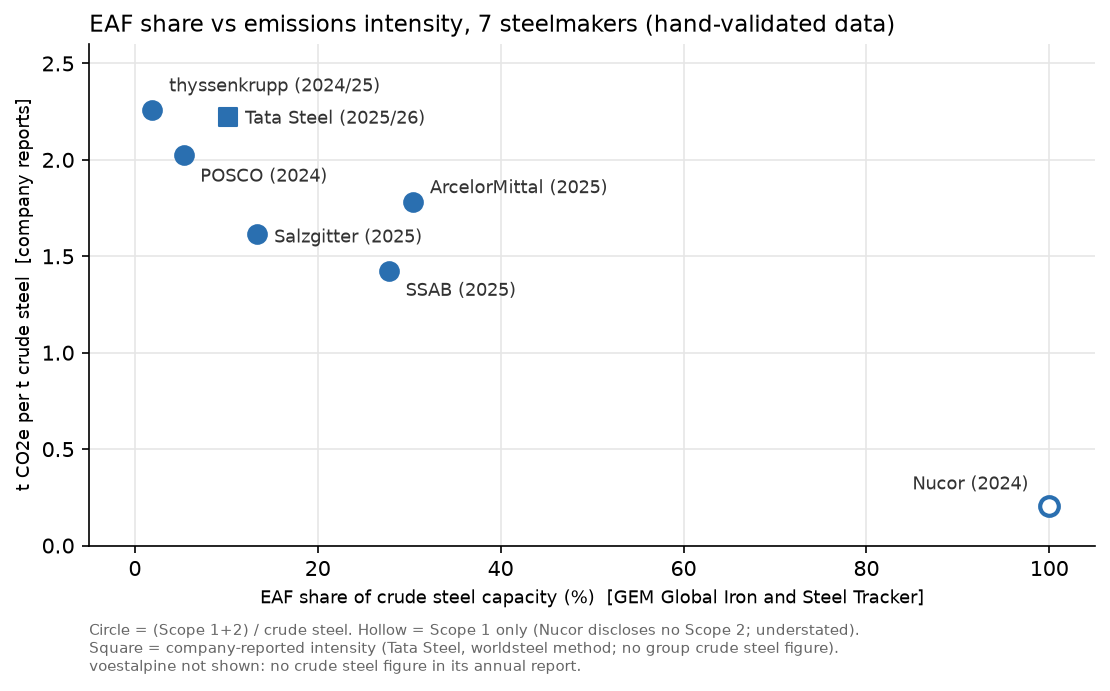

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 4.8), dpi=150)
color = "#2a6fb0"
offsets = {"thyssenkrupp": (8, 9), "Tata Steel": (8, -3), "POSCO": (8, -13),
           "Salzgitter": (8, -4), "ArcelorMittal": (8, 4), "SSAB": (8, -12), "Nucor": (-10, 8)}

for _, r in b.iterrows():
    if r.basis == "Scope 1+2":
        ax.scatter(r.eaf_pct, r.intensity, s=80, color=color, zorder=3)
    elif r.basis == "Scope 1 only":
        ax.scatter(r.eaf_pct, r.intensity, s=80, facecolor="white", edgecolor=color, linewidth=2, zorder=3)
    else:
        ax.scatter(r.eaf_pct, r.intensity, s=70, marker="s", color=color, zorder=3)
    dx, dy = offsets[r.company]
    ax.annotate(f"{r.company} ({r.year})", (r.eaf_pct, r.intensity), xytext=(dx, dy),
                textcoords="offset points", ha="right" if dx < 0 else "left",
                fontsize=8.5, color="#333333")

ax.set_xlim(-5, 105)
ax.set_ylim(0, 2.6)
ax.set_xlabel("EAF share of crude steel capacity (%)  [GEM Global Iron and Steel Tracker]", fontsize=8.5)
ax.set_ylabel("t CO2e per t crude steel  [company reports]", fontsize=8.5)
ax.set_title("EAF share vs emissions intensity, 7 steelmakers (hand-validated data)", loc="left", fontsize=11)
ax.grid(color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.text(0, -0.25,
        "Circle = (Scope 1+2) / crude steel. Hollow = Scope 1 only (Nucor discloses no Scope 2; understated).\n"
        "Square = company-reported intensity (Tata Steel, worldsteel method; no group crude steel figure).\n"
        "voestalpine not shown: no crude steel figure in its annual report.",
        transform=ax.transAxes, fontsize=7.2, color="#666666")

plt.tight_layout()
plt.savefig("../charts/eaf_vs_intensity.png", bbox_inches="tight")
plt.show()